# EDA новостей Интерфакса

## 1. Загрузка и проверка качества данных

In [1]:
import pandas as pd

news = pd.read_csv("data/news_final.csv")

# Приводим время публикации к московскому часовому поясу
news["datetime"] = (
    pd.to_datetime(news["datetime"], format="mixed", utc=True)
    .dt.tz_convert("Europe/Moscow")
)

print("Размер:", news.shape)

print("\nИнформация о данных:")
news.info()

print("\nПримеры новостей:")
display(news.head())

Размер: (34860, 11)

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 34860 entries, 0 to 34859
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype                        
---  ------            --------------  -----                        
 0   record_id         34860 non-null  str                          
 1   datetime          34860 non-null  datetime64[us, Europe/Moscow]
 2   title             34860 non-null  str                          
 3   url               34860 non-null  str                          
 4   source            34860 non-null  str                          
 5   topics            34860 non-null  str                          
 6   event_type        34860 non-null  str                          
 7   time_source       34860 non-null  str                          
 8   text              34860 non-null  str                          
 9   text_status       34860 non-null  str                          
 10  retrieved_at_utc  34860 non

,record_id,datetime,title,url,source,topics,event_type,time_source,text,text_status,retrieved_at_utc
0,interfax_https://www.interfax.ru/business/690022,2020-01-01 15:21:00+03:00,Exxon Mobil добилась в суде отмены штрафов в $...,https://www.interfax.ru/business/690022,Interfax,oil_gas,news,interfax_archive,Москва. 1 января. INTERFAX.RU - Окружной суд Д...,ok,2026-10-31T08:42:27.347606+00:00
1,interfax_https://www.interfax.ru/business/690054,2020-01-02 09:04:00+03:00,Добыча нефти в России в 2019 году повысилась н...,https://www.interfax.ru/business/690054,Interfax,oil_gas,news,interfax_archive,Москва. 2 января. INTERFAX.RU - Объем добычи ...,ok,2026-10-31T08:42:29.468689+00:00
2,interfax_https://www.interfax.ru/business/690081,2020-01-02 18:06:00+03:00,"""Газпром"" конкретизировал итоговые данные по д...",https://www.interfax.ru/business/690081,Interfax,oil_gas,news,interfax_archive,"Москва. 2 января. INTERFAX.RU - ""Газпром"" конк...",ok,2026-10-31T08:42:31.574837+00:00
3,interfax_https://www.interfax.ru/business/690116,2020-01-03 09:12:00+03:00,Экспорт нефти из России в дальнее зарубежье в ...,https://www.interfax.ru/business/690116,Interfax,oil_gas,news,interfax_archive,Москва. 3 января. INTERFAX.RU - Экспорт россий...,ok,2026-10-31T08:42:33.682120+00:00
4,interfax_https://www.interfax.ru/business/690118,2020-01-03 09:31:00+03:00,Нефть резко дорожала на новостях об убийстве и...,https://www.interfax.ru/business/690118,Interfax,oil_gas,news,interfax_archive,Москва. 3 января. INTERFAX.RU - Цены на нефть ...,ok,2026-10-31T08:42:35.829661+00:00


Проверяем на пропуски. Смотрим по record_id, url. Тут же смотрим что есть нововсти за весь искомый диапазон

In [2]:
print("Пропуски по столбцам:")
display(news.isna().sum())

# Проверяем повторяющиеся идентификаторы новостей
print("Дубликатов record_id:", news["record_id"].duplicated().sum())

# Проверяем повторяющиеся ссылки
print("Дубликатов url:", news["url"].duplicated().sum())

# Проверяем временной диапазон
print("Первая публикация:", news["datetime"].min())
print("Последняя публикация:", news["datetime"].max())

Пропуски по столбцам:


record_id           0
datetime            0
title               0
url                 0
source              0
topics              0
event_type          0
time_source         0
text                0
text_status         0
retrieved_at_utc    0
dtype: int64

Дубликатов record_id: 0
Дубликатов url: 0
Первая публикация: 2020-01-01 15:21:00+03:00
Последняя публикация: 2026-10-23 20:49:00+03:00


Все выглядит прекрасно. Дубликатов никаких нет, пропусков нет, все даты обработаны. Проверяем еще что наполнение поля text нормальное: проверяем по флагу text_status и собственно по наличию текста, что новость записалась. Заодно смотрим самые короткие новости.

In [3]:
# Проверяем статусы загрузки текстов
print("Статусы текстов:")
display(news["text_status"].value_counts())

# Проверяем пустые строки
print("Пустых текстов:", news["text"].str.strip().eq("").sum())

# Рассчитываем длину текстов в символах
news["text_length"] = news["text"].str.len()

print("\nСамые короткие тексты:")
display(
    news.nsmallest(10, "text_length")[
        ["datetime", "title", "text_status", "text_length", "text"]
    ]
)

Статусы текстов:


text_status
ok    34860
Name: count, dtype: int64

Пустых текстов: 0

Самые короткие тексты:


,datetime,title,text_status,text_length,text
11807,2022-09-05 15:21:00+03:00,Комитет ОПЕК+ рекомендовал снизить квоты добыч...,ok,147,Москва. 5 сентября. INTERFAX.RU - Министерский...
21475,2024-05-27 11:31:00+03:00,Курс евро опустился ниже 96 рублей впервые с 3...,ok,147,"Москва. 27 мая. INTERFAX.RU - Курс евро на ""Мо..."
12783,2022-11-01 10:09:00+03:00,Набсовет Московской биржи рекомендовал не выпл...,ok,179,"Москва. 1 ноября. INTERFAX.RU - Набсовет ПАО ""..."
26788,2025-04-22 13:56:00+03:00,"""Мосбиржа"" приостановила торги на срочном рынке",ok,181,Москва. 22 апреля. INTERFAX.RU - Остановлены т...
32547,2026-05-06 17:15:00+03:00,"Brent подешевела на 6,4% до $102,86 за баррель",ok,182,Москва. 6 мая. INTERFAX.RU - Нефть продолжает ...
22381,2024-07-22 11:07:00+03:00,"СД ""Северстали"" рекомендовал дивиденды за II к...",ok,189,Москва. 22 июля. INTERFAX.RU - Совет директоро...
16055,2023-06-04 18:43:00+03:00,Источники сообщили о планах ОПЕК+ продлить сог...,ok,191,Москва. 4 июня. INTERFAX.RU - Соглашение ОПЕК+...
31549,2026-02-27 08:39:00+03:00,Добыча нефти в Казахстане в 2025 году составил...,ok,195,Москва. 27 февраля. INTERFAX.RU - Казахстан до...
1146,2020-04-24 16:41:00+03:00,"Алекперов купил акции ""ЛУКОЙЛа"" на 300 млн рублей",ok,201,"Москва. 24 апреля. INTERFAX.RU - Президент ""ЛУ..."
18356,2023-11-01 10:54:00+03:00,Мобильный банк Сбербанка временно недоступен,ok,207,Москва. 1 ноября. INTERFAX.RU - Мобильный бан...


Выглядит хорошо, везде текст записался, самые короткие новости это действительно новости а не какие-то огрызки.

## 2. Характеристики новостного корпуса

### 2.1. Тематическое распределение

Смотрим, как распределены новости по тематикам

In [4]:
topic_counts = (
    news["topics"]
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

display(topic_counts)

topics
oil_gas        15147
finance         8003
macro           7233
metals          1780
mining          1629
transport        746
energy           623
it               504
telecom          431
fertilizers      425
retail           416
agriculture      183
holdings         143
healthcare        31
Name: count, dtype: int64

После разделения составных меток выяснилось, что в корпусе преобладают нефтегазовые новости (15 147 публикаций), финансовые новости (8 003) и макроэкономические новости (7 233). Одна новость может приходится на несколько топиков, поэтому полученные категории не являются взаимоисключающими

### 2.2. Распределение публикаций во времени

Посмотрим временное распределение новостей.

In [5]:
# Количество новостей по годам
print("Новости по годам:")
display(
    news["datetime"].dt.year.value_counts().sort_index()
)

# Количество новостей по часам суток
print("\nНовости по часам:")
display(
    news["datetime"].dt.hour.value_counts().sort_index()
)

Новости по годам:


datetime
2020    3396
2021    4145
2022    6173
2023    5617
2024    5732
2025    5795
2026    4002
Name: count, dtype: int64


Новости по часам:


datetime
0      175
1       72
2       53
3       44
4       48
5       49
6      102
7      823
8     2235
9     1474
10    4683
11    1933
12    1994
13    2216
14    2949
15    2627
16    2487
17    2112
18    2607
19    3987
20    1240
21     618
22     229
23     103
Name: count, dtype: int64

Сразу бросается в глаза что начиная с 22 года новостей стало побольше. 26-й не в счет, так как он не полный.
Также видно, что в течение дня значительно больше новостей в 10 утра и 19 вечера. Это говорит о том, что время публикации определенно надо будет учитывать при сопоставлении с котировками.

Важное ограничение - новости в выборке не все подряд, а отобраные по ключевым словам вокруг выбранных тикеров.

Посмотрим динамику по месяцам:

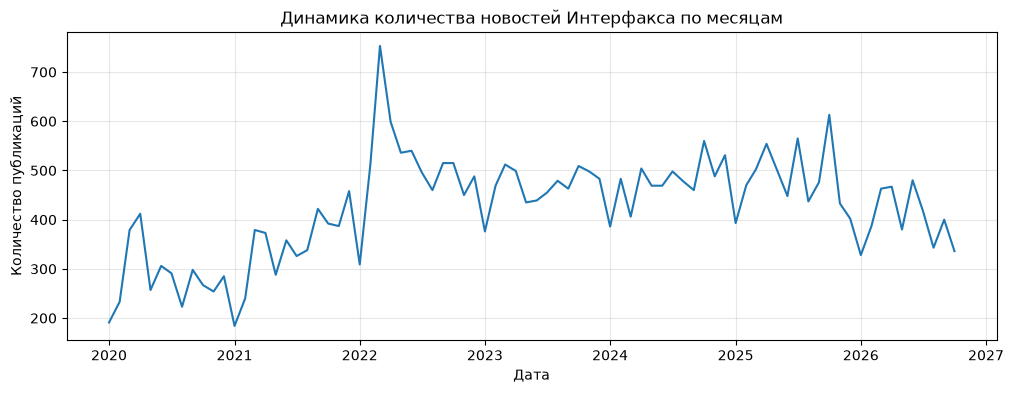

In [6]:
import matplotlib.pyplot as plt

# Количество публикаций по месяцам
news_monthly = (
    news.set_index("datetime")
    .resample("MS")
    .size()
)

plt.figure(figsize=(12, 4))
plt.plot(news_monthly.index, news_monthly.values)

plt.title("Динамика количества новостей Интерфакса по месяцам")
plt.xlabel("Дата")
plt.ylabel("Количество публикаций")
plt.grid(alpha=0.3)
plt.show()

Ну картина в целом понятная. Пик на февраль-марте 22 года. Потом явно бОльшее поличество новостей, чем в период до 22 года, это мы отмечали в годовой динамике.

### 2.3. Длина заголовков и текстов

Посмотрим на объемы текстов новостей, насколько они друг от друга отличаются:

In [7]:
# Длина заголовков и текстов в словах
news["title_words"] = news["title"].str.split().str.len()
news["text_words"] = news["text"].str.split().str.len()

print("Статистика длины заголовков:")
display(news["title_words"].describe())

print("\nСтатистика длины текстов:")
display(news["text_words"].describe())

print("\nСамые длинные статьи:")
display(
    news.nlargest(5, "text_words")[
        ["datetime", "title", "text_words"]
    ]
)

Статистика длины заголовков:


count    34860.000000
mean        10.428571
std          2.530545
min          2.000000
25%          9.000000
50%         11.000000
75%         12.000000
max         23.000000
Name: title_words, dtype: float64


Статистика длины текстов:


count    34860.000000
mean       376.709323
std        371.013647
min         21.000000
25%        168.000000
50%        247.000000
75%        395.000000
max       6049.000000
Name: text_words, dtype: float64


Самые длинные статьи:


,datetime,title,text_words
676,2020-03-21 02:00:00+03:00,Заявление Банка России: ключевую ставку посади...,6049
253,2020-02-07 22:30:00+03:00,"Заявление Банка России: Времена меняются, и ст...",4795
3384,2020-12-30 17:24:00+03:00,Электроэнергетика одна дома в ожидании новогод...,4155
8709,2022-03-15 19:34:00+03:00,Инвесторы ждут торгов на Мосбирже в надежде на...,4092
16781,2023-07-21 21:15:00+03:00,Заявление Банка России: Экономика оправдывает ...,3827


В целом как будто бы нормально, но выбивается то, что средняя длина текстов по словам больше медианы в полтора раза. Это можно интерпретировать наличием колоссальных талмудов например на тему заявлений Банка России (как в выведенном примере). У этих статей кстати количество слов действительно огромное относительно и медианы и среднего значения.

## 3. Предобработка текстов

### 3.1. Токенизация

Наконец переходим к интересному - попытки в NLP. Для начала на примере одной самой первой статьи проведем токенизацию и лемматизацию

In [8]:
import re

# Берём текст первой статьи
sample_text = news.loc[0, "text"]

# Приводим к нижнему регистру и выделяем слова
tokens = re.findall(r"[а-яёa-z]+", sample_text.lower())

print("Первые 40 токенов:")
print(tokens[:40])

print("\nВсего токенов:", len(tokens))

Первые 40 токенов:
['москва', 'января', 'interfax', 'ru', 'окружной', 'суд', 'далласа', 'отменил', 'штрафы', 'в', 'млн', 'которую', 'минфин', 'сша', 'наложил', 'на', 'нефтяную', 'корпорацию', 'exxon', 'mobil', 'за', 'сделки', 'с', 'роснефтью', 'вопреки', 'санкциям', 'введенным', 'против', 'главы', 'компании', 'игоря', 'сечина', 'об', 'этом', 'сообщает', 'bloomberg', 'со', 'ссылкой', 'на', 'решение']

Всего токенов: 147


### 3.2. Удаление стоп-слов

Отфильтруем стоп-слова. Осуществим это при помощи либы stop_words

In [9]:
from stop_words import get_stop_words

# Список русских стоп-слов
stop_words = set(get_stop_words("ru"))

# Убираем стоп-слова и короткие токены
filtered_tokens = [
    word for word in tokens
    if word not in stop_words and len(word) > 1
]

print("До очистки:", len(tokens))
print("После очистки:", len(filtered_tokens))

print("\nПервые 40 токенов после очистки:")
print(filtered_tokens[:40])

До очистки: 147
После очистки: 92

Первые 40 токенов после очистки:
['москва', 'января', 'interfax', 'ru', 'окружной', 'суд', 'далласа', 'отменил', 'штрафы', 'млн', 'которую', 'минфин', 'сша', 'наложил', 'нефтяную', 'корпорацию', 'exxon', 'mobil', 'сделки', 'роснефтью', 'вопреки', 'санкциям', 'введенным', 'главы', 'компании', 'игоря', 'сечина', 'сообщает', 'bloomberg', 'ссылкой', 'решение', 'судьи', 'джейн', 'бойл', 'мнению', 'судьи', 'exxon', 'достаточным', 'образом', 'проинформирована']


### 3.3. Лемматизация

Лемматизация. Используем pymorphy3

In [10]:
import pymorphy3

morph = pymorphy3.MorphAnalyzer()

# Приводим очищенные токены к начальной форме
lemmas = [
    morph.parse(word)[0].normal_form
    for word in filtered_tokens
]

print("До лемматизации:")
print(filtered_tokens[:30])

print("\nПосле лемматизации:")
print(lemmas[:30])

До лемматизации:
['москва', 'января', 'interfax', 'ru', 'окружной', 'суд', 'далласа', 'отменил', 'штрафы', 'млн', 'которую', 'минфин', 'сша', 'наложил', 'нефтяную', 'корпорацию', 'exxon', 'mobil', 'сделки', 'роснефтью', 'вопреки', 'санкциям', 'введенным', 'главы', 'компании', 'игоря', 'сечина', 'сообщает', 'bloomberg', 'ссылкой']

После лемматизации:
['москва', 'январь', 'interfax', 'ru', 'окружный', 'суд', 'даллас', 'отменить', 'штраф', 'млн', 'который', 'минфин', 'сша', 'наложить', 'нефтяной', 'корпорация', 'exxon', 'mobil', 'сделка', 'роснефть', 'вопреки', 'санкция', 'ввести', 'глава', 'компания', 'игорь', 'сечин', 'сообщать', 'bloomberg', 'ссылка']


### 3.4. Обработка всего корпуса

Экстраполируем на все остальные новости. Для лемматизации используем кеш, чтобы по нескольку раз одни и те же слова не гонять.

In [11]:
from functools import lru_cache

# Кэшируем лемматизацию, чтобы не обрабатывать одинаковые слова повторно
@lru_cache(maxsize=100_000)
def lemmatize(word):
    if word.isascii():
        return word
    return morph.parse(word)[0].normal_form


def preprocess_text(text):
    # Удаляем стандартную шапку Интерфакса
    text = re.sub(
        r"^[^.]{1,60}\.\s*\d{1,2}\s+[а-яё]+\.\s*INTERFAX\.RU\s*[-–—]\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    # Токенизация
    tokens = re.findall(r"[а-яёa-z]+", text.lower())

    # Удаление стоп-слов и лемматизация
    lemmas = []
    for word in tokens:
        if len(word) <= 1 or word in {"interfax", "ru"}:
            continue

        if word in stop_words and word not in {"не", "ни"}:
            continue

        lemma = lemmatize(word)

        if lemma not in stop_words or lemma in {"не", "ни"}:
            lemmas.append(lemma)

    return " ".join(lemmas)


# Применяем ко всем статьям
news["clean_text"] = news["text"].apply(preprocess_text)

print("Исходный текст:")
print(news.loc[0, "text"][:400])

print("\nОбработанный текст:")
print(news.loc[0, "clean_text"][:400])

print("\nОбработано статей:", news["clean_text"].notna().sum())

Исходный текст:
Москва. 1 января. INTERFAX.RU - Окружной суд Далласа отменил штрафы в $2 млн, которую Минфин США наложил на нефтяную корпорацию Exxon Mobil за сделки с "Роснефтью" вопреки санкциям, введенным против главы компании Игоря Сечина. Об этом сообщает Bloomberg со ссылкой на решение судьи Джейн Бойл.
По мнению судьи, Exxon не была достаточным образом проинформирована, что ее соглашения, заключенные с "Ро

Обработанный текст:
окружный суд даллас отменить штраф млн минфин сша наложить нефтяной корпорация exxon mobil сделка роснефть вопреки санкция ввести глава компания игорь сечин сообщать bloomberg ссылка решение судья джейн бойло мнение судья exxon не достаточный образ проинформировать соглашение заключить роснефть нарушить ограничение ввести крым exxon иск указать незаконно наказать сотрудничество роснефть не санкция

Обработано статей: 34860


Выглядит неплохо, в выведенном примере только Джейн Бойл не повезло, но видится, что это не критично

## 4. Частотный анализ

### 4.1. Частотность отдельных слов

Теперь частотный анализ:

In [12]:
from collections import Counter

# Проверяем, что после очистки не осталось пустых текстов
print("Пустых после обработки:", news["clean_text"].eq("").sum())

# Считаем частоту каждого слова во всех статьях
word_counts = Counter()

for text in news["clean_text"]:
    word_counts.update(text.split())

# Показываем 30 самых частых слов
word_freq = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "count"]
)

display(word_freq)

Пустых после обработки: 0


,word,count
0,рубль,87773
1,нефть,73784
2,рынок,69239
3,не,65633
4,цена,60887
5,млрд,58388
6,млн,56670
7,компания,55735
8,баррель,55005
9,сша,53618


Видим, что преобладают слова экономической тематики, что соответствует методу отбора новостей. Явно выделяются слова нефтегазовой тематики, что тоже объяснимо. 
Очень много "не", но как будто бы не нужно это исправлять, так как для выявления смысла из текста это важная частица. Также много слов общей и общефинансовой тматики - млрд, руб, объем и тд и тп. 

### 4.2. Биграммы

Посмотрим сочетания слов. Будем смотреть на заголовках, так как обрабатываемого текста поменьше, а смысл статей они должны передавать

In [13]:
# Считаем частоты биграмм в заголовках
bigram_counts = Counter()

for title in news["title"]:
    words = preprocess_text(title).split()
    bigram_counts.update(zip(words, words[1:]))

# Выводим 20 самых частых сочетаний
bigram_freq = pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in bigram_counts.most_common(20)
    ],
    columns=["bigram", "count"]
)

display(bigram_freq)

,bigram,count
0,индекс мосбиржа,2390
1,рынок акция,2030
2,акция рф,1754
3,brent подорожать,1218
4,подорожать баррель,1181
5,доллар евро,1154
6,цена нефть,1131
7,мосбиржа ртс,1075
8,brent подешеветь,1046
9,подешеветь баррель,1014


Биграммы вышли вполне осмысленные, все на экономическую тематику. Преобладают общие финансовые новости. Очень много нефтянки. 

## 5. Числовое представление текстов

### 5.1. Bag of Words

Возьмем самые популярные 5000 слов и составим BoW для них. Выведем для примера результат для первой статьи из выборки.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

# Создаём Bag of Words для всех статей
vectorizer = CountVectorizer(
    min_df=10,
    max_features=5000
)

bow = vectorizer.fit_transform(news["clean_text"])

print("Размер матрицы BoW:", bow.shape)
print("Ненулевых элементов:", bow.nnz)

# Посмотрим, какие слова встретились в первой статье
words = vectorizer.get_feature_names_out()
first_article = bow.getrow(0)

example = pd.DataFrame({
    "word": words[first_article.indices],
    "count": first_article.data
})

display(
    example.sort_values("count", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

Размер матрицы BoW: (34860, 5000)
Ненулевых элементов: 4829145


,word,count
0,exxon,5
1,минфин,3
2,санкция,3
3,ввести,3
4,роснефть,3
5,не,3
6,сша,2
7,bloomberg,2
8,решение,2
9,сечин,2


### 5.2. TF-IDF

In [15]:
from sklearn.feature_extraction.text import TfidfTransformer

# Преобразуем готовую матрицу BoW в TF-IDF
tfidf_transformer = TfidfTransformer()
tfidf = tfidf_transformer.fit_transform(bow)

print("Размер матрицы TF-IDF:", tfidf.shape)
print("Ненулевых элементов:", tfidf.nnz)

# Смотрим слова с наибольшим TF-IDF в первой статье
first_article_tfidf = tfidf.getrow(0)

tfidf_example = pd.DataFrame({
    "word": words[first_article_tfidf.indices],
    "tfidf": first_article_tfidf.data
})

display(
    tfidf_example
    .sort_values("tfidf", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

Размер матрицы TF-IDF: (34860, 5000)
Ненулевых элементов: 4829145


,word,tfidf
0,exxon,0.663618
1,сечин,0.238253
2,минфин,0.202818
3,роснефть,0.189641
4,ввести,0.185217
5,санкция,0.165530
6,заключить,0.143009
7,bloomberg,0.135521
8,приветствовать,0.130748
9,mobil,0.126915


## Общий вывод по EDA новостей

Были проанализированы 34 860 новостей Интерфакса за период с января 2020 года по октябрь 2026 года.

Проверка качества не выявила пропусков и дублей.

Анализ временного показал увеличение количества новостей с 2022 года. Наиболее заметный пик пришелся на февраль-март 22 года. Также выявлена неравномерность распределения новостей в течение дня.

Тематический и частотный анализ показал, что в имеющемся корпусе преобладают новости экономической и нефтегазовой тематики. 

Выполнены токенизация, лемматизация, проанализированы частоты слов и би-граммы, собраны Bag of Words и TF-IDF.